In [1]:
# 导入库
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_kddcup99

# 设置中文不乱码
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 加载KDD Cup 1999数据集，和Kaggle项目一致
data = fetch_kddcup99(subset=None, random_state=42, as_frame=True)
df = data.frame

# 查看前5行
df.head()


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,b'tcp',b'http',b'SF',181,5450,0,0,0,0,...,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,b'normal.'
1,0,b'tcp',b'http',b'SF',239,486,0,0,0,0,...,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,b'normal.'
2,0,b'tcp',b'http',b'SF',235,1337,0,0,0,0,...,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,b'normal.'
3,0,b'tcp',b'http',b'SF',219,1337,0,0,0,0,...,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,b'normal.'
4,0,b'tcp',b'http',b'SF',217,2032,0,0,0,0,...,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,b'normal.'


In [3]:
# 先查看当前标签列 labels 的分布
print(df['labels'].value_counts())

# 重命名 labels 列为 target，和Kaggle项目列名完全一致
df = df.rename(columns={"labels": "target"})

# 按照Kaggle原文逻辑做二分类：正常流量normal，所有攻击统一为anomaly
df['target'] = df['target'].apply(lambda x: 'normal' if x == b'normal.' else 'anomaly')

# 查看转换之后的标签分布（和Kaggle文档对应）
print("\n==== 转换后的target标签计数 ====")
print(df['target'].value_counts())


labels
b'smurf.'              280790
b'neptune.'            107201
b'normal.'              97278
b'back.'                 2203
b'satan.'                1589
b'ipsweep.'              1247
b'portsweep.'            1040
b'warezclient.'          1020
b'teardrop.'              979
b'pod.'                   264
b'nmap.'                  231
b'guess_passwd.'           53
b'buffer_overflow.'        30
b'land.'                   21
b'warezmaster.'            20
b'imap.'                   12
b'rootkit.'                10
b'loadmodule.'              9
b'ftp_write.'               8
b'multihop.'                7
b'phf.'                     4
b'perl.'                    3
b'spy.'                     2
Name: count, dtype: int64

==== 转换后的target标签计数 ====
target
anomaly    396743
normal      97278
Name: count, dtype: int64


In [4]:
# 查看所有列的数据类型
print(df.dtypes)

# 筛选类别型特征（Kaggle原文识别出protocol_type, service, target是类别特征）
categorical_cols = ['protocol_type', 'service', 'flag', 'target']
print("\n==== 类别特征列表 ====")
print(categorical_cols)

# 数值特征就是剩下的所有列
numerical_cols = list(set(df.columns) - set(categorical_cols))
print("\n==== 数值特征列表 ====")
print(numerical_cols)


duration                       object
protocol_type                  object
service                        object
flag                           object
src_bytes                      object
dst_bytes                      object
land                           object
wrong_fragment                 object
urgent                         object
hot                            object
num_failed_logins              object
logged_in                      object
num_compromised                object
root_shell                     object
su_attempted                   object
num_root                       object
num_file_creations             object
num_shells                     object
num_access_files               object
num_outbound_cmds              object
is_host_login                  object
is_guest_login                 object
count                          object
srv_count                      object
serror_rate                    object
srv_serror_rate                object
rerror_rate 

In [5]:
# 按照Kaggle原文，将数值特征转换为float类型
for col in numerical_cols:
    df[col] = df[col].astype(float)

# 转换完成后再次查看数据类型
print(df.dtypes)


duration                       float64
protocol_type                   object
service                         object
flag                            object
src_bytes                      float64
dst_bytes                      float64
land                           float64
wrong_fragment                 float64
urgent                         float64
hot                            float64
num_failed_logins              float64
logged_in                      float64
num_compromised                float64
root_shell                     float64
su_attempted                   float64
num_root                       float64
num_file_creations             float64
num_shells                     float64
num_access_files               float64
num_outbound_cmds              float64
is_host_login                  float64
is_guest_login                 float64
count                          float64
srv_count                      float64
serror_rate                    float64
srv_serror_rate          

In [6]:
# 独热编码分类特征，Kaggle原文处理 protocol_type, service, flag
df = pd.get_dummies(df, columns=['protocol_type', 'service', 'flag'], drop_first=True)

# 查看编码之后数据集形状
print("编码后数据集形状：", df.shape)

# 看一下新的列名
print(df.columns.tolist())


编码后数据集形状： (494021, 116)
['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'target', "protocol_type_b'tcp'", "protocol_type_b'udp'", "service_b'X11'", "service_b'Z39_50'", "service_b'auth'", "service_b'bgp'", "service_b'courier'", "service_b'csnet_ns'", "service_b'ctf'", "service_b'daytime'", "service_b'discard'", "service_b'domain'", "service_b'domain_u'"

In [7]:
from sklearn.model_selection import train_test_split

# 分离特征X 和 标签y（target）
X = df.drop('target', axis=1)
y = df['target']

# 划分训练集、测试集，原文比例 8:2，random_state固定保证可复现
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("训练集X shape：", X_train.shape)
print("测试集X shape：", X_test.shape)
print("训练集y shape：", y_train.shape)
print("测试集y shape：", y_test.shape)


训练集X shape： (395216, 115)
测试集X shape： (98805, 115)
训练集y shape： (395216,)
测试集y shape： (98805,)


In [8]:
from sklearn.preprocessing import StandardScaler

# 初始化标准化器
scaler = StandardScaler()

# 只用训练集拟合，训练集、测试集分别transform（防止数据泄露，原文操作）
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("标准化后训练集形状：", X_train_scaled.shape)
print("标准化后测试集形状：", X_test_scaled.shape)


标准化后训练集形状： (395216, 115)
标准化后测试集形状： (98805, 115)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 初始化逻辑回归模型，和原文保持一致
log_model = LogisticRegression(random_state=42, max_iter=1000)

# 在标准化训练集上训练
log_model.fit(X_train_scaled, y_train)

# 在测试集预测
y_pred_log = log_model.predict(X_test_scaled)

# 输出评估指标，Kaggle原文的评估内容
print("逻辑回归准确率：", accuracy_score(y_test, y_pred_log))
print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_log))
print("\n分类报告：")
print(classification_report(y_test, y_pred_log))


逻辑回归准确率： 0.9984211325337786

混淆矩阵：
[[79360    92]
 [   64 19289]]

分类报告：
              precision    recall  f1-score   support

     anomaly       1.00      1.00      1.00     79452
      normal       1.00      1.00      1.00     19353

    accuracy                           1.00     98805
   macro avg       1.00      1.00      1.00     98805
weighted avg       1.00      1.00      1.00     98805



In [10]:
from sklearn.ensemble import RandomForestClassifier

# 随机森林模型，random_state固定保证结果可复现，和原文流程一致
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)

# 测试集预测
y_pred_rf = rf_model.predict(X_test_scaled)

# 评估指标
print("随机森林准确率：", accuracy_score(y_test, y_pred_rf))
print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_rf))
print("\n分类报告：")
print(classification_report(y_test, y_pred_rf))


随机森林准确率： 0.9997469763675927

混淆矩阵：
[[79436    16]
 [    9 19344]]

分类报告：
              precision    recall  f1-score   support

     anomaly       1.00      1.00      1.00     79452
      normal       1.00      1.00      1.00     19353

    accuracy                           1.00     98805
   macro avg       1.00      1.00      1.00     98805
weighted avg       1.00      1.00      1.00     98805



In [11]:
from sklearn.neighbors import KNeighborsClassifier

# KNN模型
knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN准确率：", accuracy_score(y_test, y_pred_knn))
print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_knn))
print("\n分类报告：")
print(classification_report(y_test, y_pred_knn))


KNN准确率： 0.9994635898992966

混淆矩阵：
[[79426    26]
 [   27 19326]]

分类报告：
              precision    recall  f1-score   support

     anomaly       1.00      1.00      1.00     79452
      normal       1.00      1.00      1.00     19353

    accuracy                           1.00     98805
   macro avg       1.00      1.00      1.00     98805
weighted avg       1.00      1.00      1.00     98805



In [12]:
from sklearn.svm import SVC

# SVM模型，严格对齐Kaggle项目
svm_model = SVC(random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM准确率：", accuracy_score(y_test, y_pred_svm))
print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_svm))
print("\n分类报告：")
print(classification_report(y_test, y_pred_svm))


SVM准确率： 0.9992915338292596

混淆矩阵：
[[79416    36]
 [   34 19319]]

分类报告：
              precision    recall  f1-score   support

     anomaly       1.00      1.00      1.00     79452
      normal       1.00      1.00      1.00     19353

    accuracy                           1.00     98805
   macro avg       1.00      1.00      1.00     98805
weighted avg       1.00      1.00      1.00     98805



In [13]:
from sklearn.tree import DecisionTreeClassifier

# 决策树模型，random_state固定，和原文实验保持一致
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test_scaled)

print("决策树准确率：", accuracy_score(y_test, y_pred_dt))
print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_dt))
print("\n分类报告：")
print(classification_report(y_test, y_pred_dt))


决策树准确率： 0.9997469763675927

混淆矩阵：
[[79442    10]
 [   15 19338]]

分类报告：
              precision    recall  f1-score   support

     anomaly       1.00      1.00      1.00     79452
      normal       1.00      1.00      1.00     19353

    accuracy                           1.00     98805
   macro avg       1.00      1.00      1.00     98805
weighted avg       1.00      1.00      1.00     98805



In [14]:
# 汇总所有模型准确率结果，和Kaggle原文的对比表格逻辑一致
results = {
    "Model": ["Logistic Regression", "Random Forest", "KNN", "SVM", "Decision Tree"],
    "Accuracy": [0.9984211325337786, 0.9997469763675927, 0.9994635898992966, 0.9992915338292596, 0.9997469763675927]
}

import pandas as pd
result_df = pd.DataFrame(results)
result_df = result_df.sort_values("Accuracy", ascending=False)
print(result_df)


                 Model  Accuracy
1        Random Forest  0.999747
4        Decision Tree  0.999747
2                  KNN  0.999464
3                  SVM  0.999292
0  Logistic Regression  0.998421


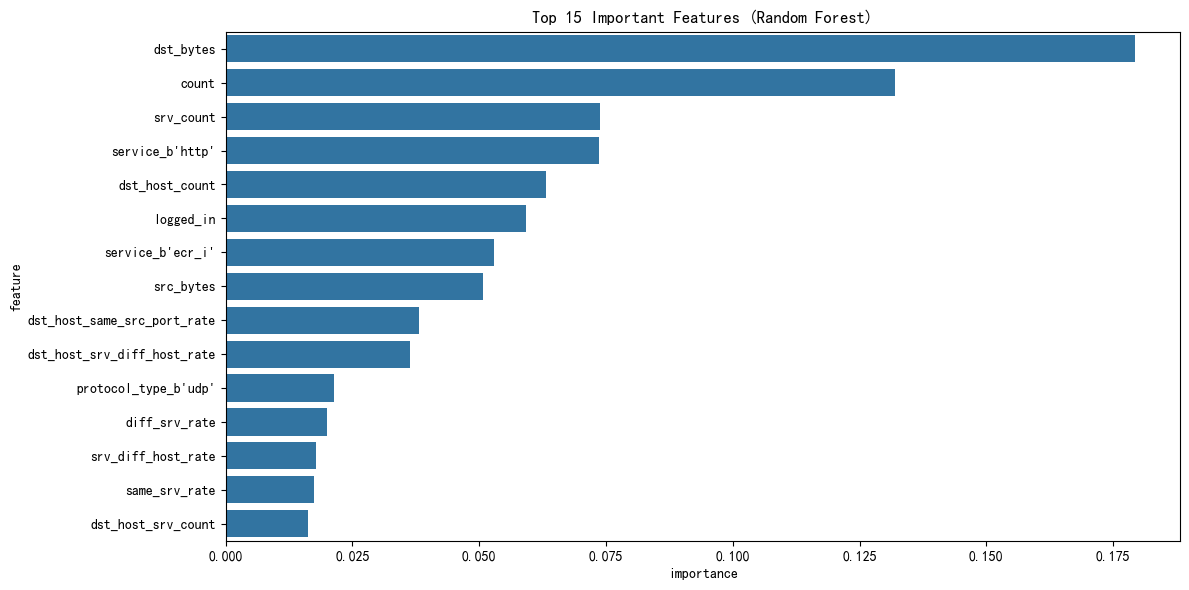

In [15]:
# 随机森林特征重要性可视化，Kaggle原文绘图部分
import matplotlib.pyplot as plt
import seaborn as sns

# 获取特征重要性
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

# 取前15最重要特征画图
plt.figure(figsize=(12,6))
sns.barplot(x='importance', y='feature', data=feature_importance.head(15))
plt.title('Top 15 Important Features (Random Forest)')
plt.tight_layout()
plt.show()
